## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('../data/ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

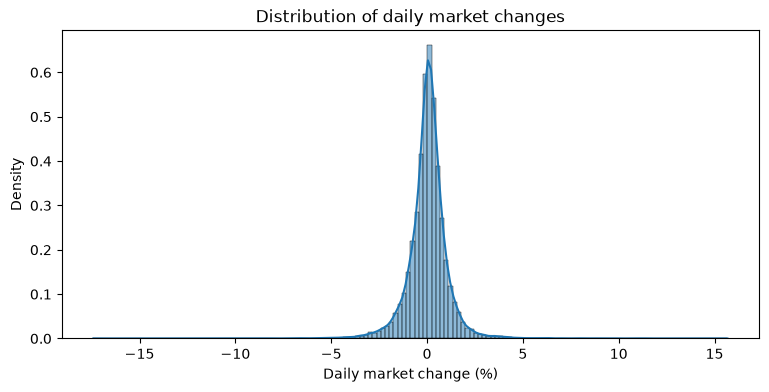

In [2]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

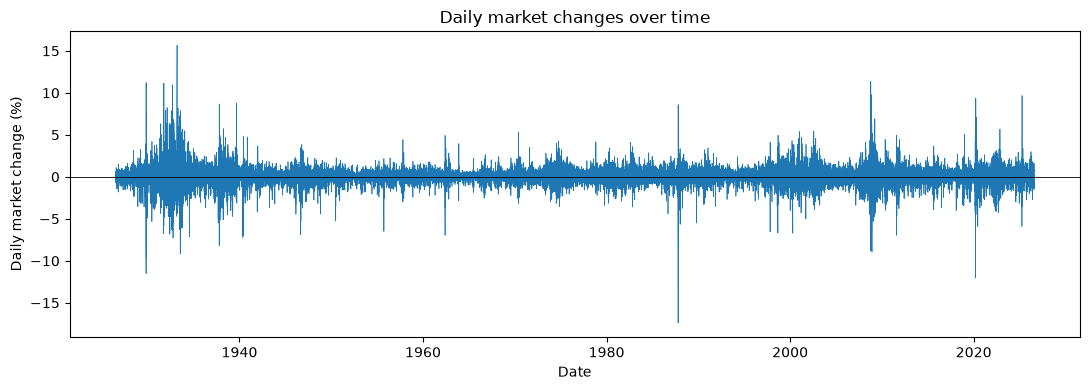

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [4]:
# My Q1 Two States Code

df['current_return_pct'] = df['market_return_pct']
df['next_day_return_pct'] = df['market_return_pct'].shift(-1)

df['current_direction'] = (df['current_return_pct'] > 0).map({False: 'Down (and flat)', True: 'Up'})
df['next_day_direction'] = df['current_direction'].shift(-1)

joint_pmf = pd.crosstab(df['current_direction'], df['next_day_direction'], normalize=True, margins=True)
print('Joint PMF and marginals')
display(joint_pmf)

conditional_pmf = pd.crosstab(df['current_direction'], df['next_day_direction'], normalize='index')
print('Conditional PMF')
display(conditional_pmf)

Joint PMF and marginals


next_day_direction,Down (and flat),Up,All
current_direction,,,
Down (and flat),0.224720,0.228142,0.452862
Up,0.228142,0.318996,0.547138
All,0.452862,0.547138,1.000000


Conditional PMF


next_day_direction,Down (and flat),Up
current_direction,,
Down (and flat),0.496221,0.503779
Up,0.416974,0.583026


## Q1 Two States 

Q 1.1 & Q 1.2 (All Code)

Q 1.3 & Q 1.4

Up transitions are more common than down transitions and their respective marginal probabilities are 0.547138 and 0.452862. Additionally, I would say that you are more likely to transition to an up day from another up day since the conditional probability is 0.583026 after an up day, compared with 0.503779 after a down day.

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [5]:
# My Q2 Binning a Continuous Variable Code

df['current_return_category'] = pd.cut(
    df['market_return_pct'],
    bins=[-np.inf, -1, -0.1, 0.1, 1, np.inf],
    labels=['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain'])

df['next_day_return_category'] = df['current_return_category'].shift(-1)
df['next_day_return_pct'] = df['market_return_pct'].shift(-1)

category_counts = df['current_return_category'].value_counts(sort=False)
print('Number of days in each bin')
display(category_counts)

category_joint_pmf = pd.crosstab(df['current_return_category'], df['next_day_return_category'], normalize=True, margins=True)
print('Joint PMF and marginals')
display(category_joint_pmf)

category_conditional_pmf = pd.crosstab(df['current_return_category'], df['next_day_return_category'], normalize='index')
print('Conditional PMF')
display(category_conditional_pmf)

next_day_summary_by_category = df.groupby('current_return_category', observed=False)['next_day_return_pct'].describe()
print('Next-day returns by current state')
display(next_day_summary_by_category)

Number of days in each bin


current_return_category
Large loss    2759
Small loss    7452
Near zero     3441
Small gain    9785
Large gain    2859
Name: count, dtype: int64

Joint PMF and marginals


next_day_return_category,Large loss,Small loss,Near zero,Small gain,Large gain,All
current_return_category,,,,,,
Large loss,0.021335,0.027191,0.009051,0.027800,0.019547,0.104925
Small loss,0.035444,0.088648,0.034151,0.097775,0.027382,0.283400
Near zero,0.009317,0.041985,0.020955,0.049325,0.009279,0.130861
Small gain,0.024986,0.100057,0.055029,0.159422,0.032592,0.372086
Large gain,0.013843,0.025518,0.011637,0.037802,0.019928,0.108728
All,0.104925,0.283400,0.130823,0.372124,0.108728,1.000000


Conditional PMF


next_day_return_category,Large loss,Small loss,Near zero,Small gain,Large gain
current_return_category,,,,,
Large loss,0.203335,0.259152,0.086263,0.264951,0.186299
Small loss,0.125067,0.312802,0.120505,0.345008,0.096618
Near zero,0.071200,0.320837,0.160128,0.376925,0.070910
Small gain,0.067150,0.268908,0.147895,0.428455,0.087592
Large gain,0.127317,0.234697,0.107030,0.347674,0.183281


Next-day returns by current state


,count,mean,std,min,25%,50%,75%,max
current_return_category,,,,,,,,
Large loss,2759.0,-0.038311,1.720570,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.043814,1.009529,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.015013,0.826054,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.106810,0.832186,-8.25,-0.25,0.12,0.50,8.67
Large gain,2859.0,0.163092,1.384086,-12.00,-0.37,0.15,0.73,15.67


## Q2 Binning a Continuous Variable

Q 2.1

The bins contain 2,759 Large loss days, 7,452 Small loss days, 3,441 Near zero days, 9,785 Small gain days, and 2,859 Large gain days. Small gain is the most common category, and Large loss is the least common.

Q 2.2

The most likely joint transition is Small gain to Small gain, with probability 0.159422. The next most likely transitions are Small gain to Small loss, with probability 0.100057, followed by Small loss to Small gain, with probability 0.097775.

Q 2.3

For each current state, the two most likely future states are:
- Large loss: Small gain (0.264951), followed by Small loss (0.259152).
- Small loss: Small gain (0.345008), followed by Small loss (0.312802).
- Near zero: Small gain (0.376925), followed by Small loss (0.320837).
- Small gain: Small gain (0.428455), followed by Small loss (0.268908).
- Large gain: Small gain (0.347674), followed by Small loss (0.234697).

The Large loss row is closest to a uniform PMF, although its Near zero probability of 0.086263 is noticeably below 0.2. The Large gain row is somewhat uneven, particularly because it favors Small gain. The Small loss row places considerably more probability on Small gain and Small loss than on the other outcomes. The Near zero and Small gain rows depart strongly from uniformity, especially by favoring Small gain and assigning low probabilities to large movements. Predicting the next state is still difficult because even the most likely outcome in each row has probability below 0.5. 

Q 2.4

Given the current state, the estimated conditional expectations of tomorrow's return are -0.038311% after Large loss, -0.043814% after Small loss, 0.015013% after Near zero, 0.106810% after Small gain, and 0.163092% after Large gain.

The observed next-day minimum and maximum returns are:
- Large loss: -17.41% to 11.22%.
- Small loss: -11.23% to 11.36%.
- Near zero: -8.19% to 5.49%.
- Small gain: -8.25% to 8.67%.
- Large gain: -12.00% to 15.67%.

The widest ranges occur after Large loss and Large gain, while the narrowest range occurs after Near zero. Every current state is followed by both positive and negative returns. I noticed that the next-day standard deviation is highest after Large loss at 1.720570, followed by Large gain at 1.384086, Small loss at 1.009529, Small gain at 0.832186, and Near zero at 0.826054. This pattern indicates volatility clustering, meaning large movements today tend to be followed by greater variability tomorrow, even though the direction remains uncertain.

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

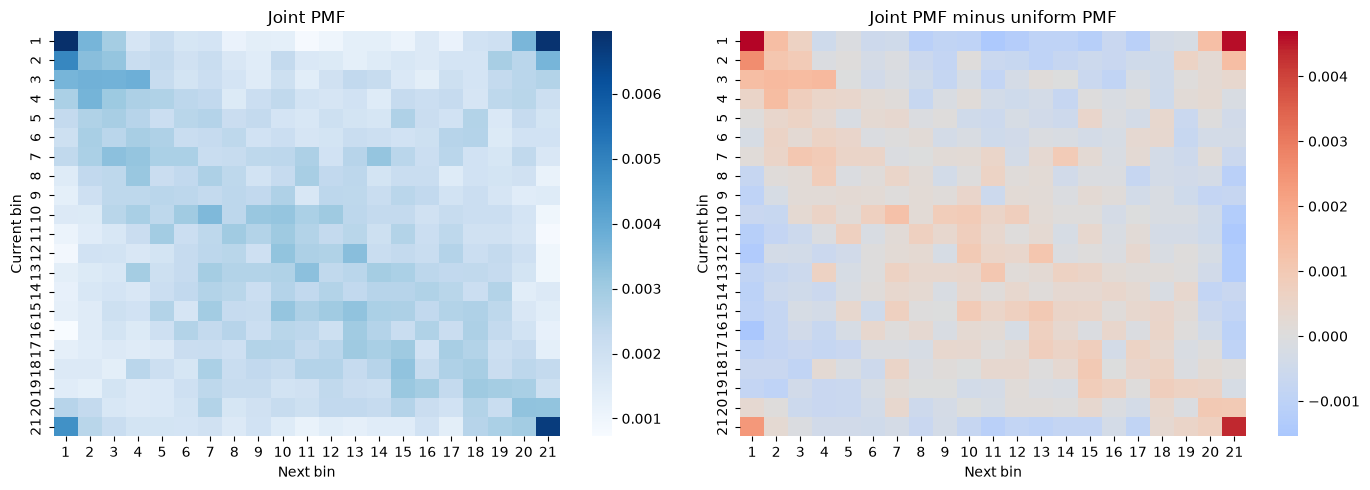

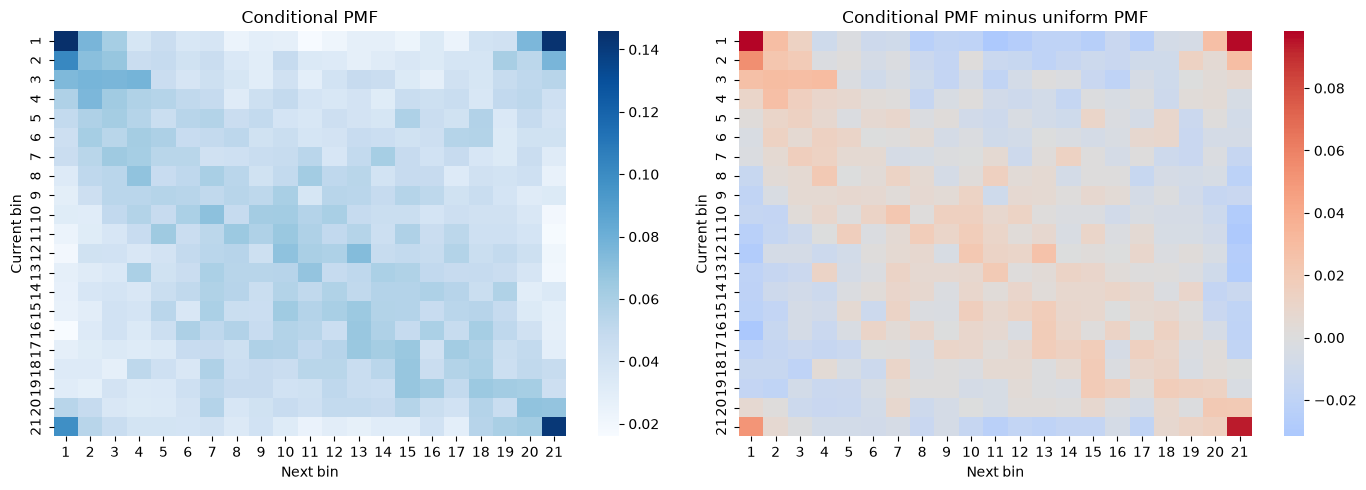

,min,mean,max,std
y_t,,,,
1,-17.41,-0.013713,11.22,2.140465
2,-7.36,-0.076712,6.36,1.285882
3,-8.79,-0.097084,11.36,1.227976
4,-8.28,-0.058594,6.16,1.049607
5,-6.89,-0.024211,4.56,0.989470
6,-11.23,-0.022692,6.37,1.024761
7,-3.94,-0.030241,7.37,0.930389
8,-3.40,-0.014303,4.76,0.835663
9,-6.00,0.025860,5.49,0.853220


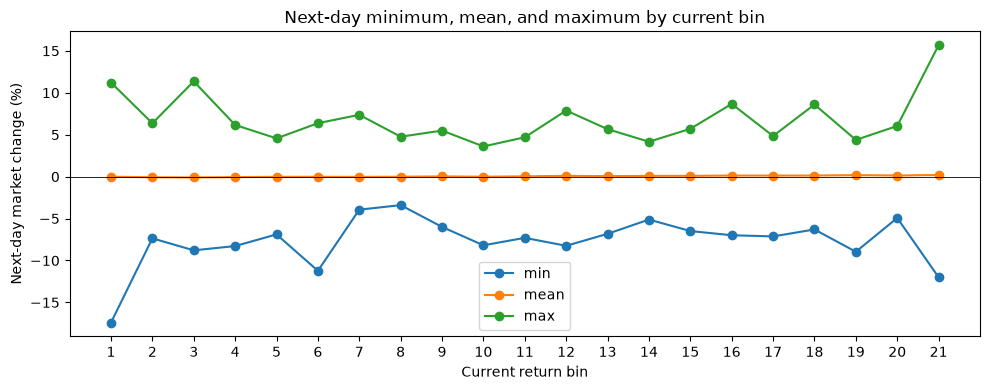

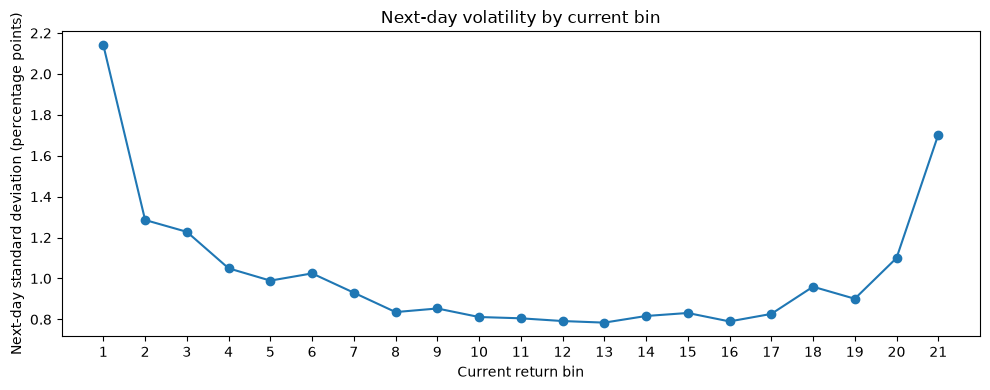

In [6]:
# My Q3 Scaling Up Code

df['y_t'] = pd.qcut(df['market_return_pct'], q=21, labels=range(1, 22))
df['y_tp1'] = df['y_t'].shift(-1)
df['next_day_return_pct'] = df['market_return_pct'].shift(-1)

quantile_joint_pmf = pd.crosstab(df['y_t'], df['y_tp1'], normalize=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(quantile_joint_pmf, cmap='Blues', ax=axes[0])
sns.heatmap(quantile_joint_pmf - 1 / 21**2, cmap='coolwarm', center=0, ax=axes[1])
axes[0].set(title='Joint PMF', xlabel='Next bin', ylabel='Current bin')
axes[1].set(title='Joint PMF minus uniform PMF', xlabel='Next bin', ylabel='Current bin')
fig.tight_layout()
plt.show()

quantile_conditional_pmf = pd.crosstab(df['y_t'], df['y_tp1'], normalize='index')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(quantile_conditional_pmf, cmap='Blues', ax=axes[0])
sns.heatmap(quantile_conditional_pmf - 1 / 21, cmap='coolwarm', center=0, ax=axes[1])
axes[0].set(title='Conditional PMF', xlabel='Next bin', ylabel='Current bin')
axes[1].set(title='Conditional PMF minus uniform PMF', xlabel='Next bin', ylabel='Current bin')
fig.tight_layout()
plt.show()

next_day_summary_by_bin = df.groupby('y_t', observed=False)['next_day_return_pct'].describe()
display(next_day_summary_by_bin[['min', 'mean', 'max', 'std']])
bin_numbers = next_day_summary_by_bin.index.astype(int)

fig, ax = plt.subplots(figsize=(10, 4))
for statistic in ['min', 'mean', 'max']:
    ax.plot(bin_numbers, next_day_summary_by_bin[statistic], marker='o', label=statistic)

ax.axhline(0, color='black', linewidth=0.6)
ax.set(title='Next-day minimum, mean, and maximum by current bin', 
       xlabel='Current return bin', ylabel='Next-day market change (%)')
ax.set_xticks(range(1, 22))
ax.legend()
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(bin_numbers, next_day_summary_by_bin['std'], marker='o')
ax.set(title='Next-day volatility by current bin',
       xlabel='Current return bin', ylabel='Next-day standard deviation (percentage points)')
ax.set_xticks(range(1, 22))
fig.tight_layout()
plt.show()

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

## Q3 Scaling Up

Q 3.1 (All Code)

Q 3.2 

I can see that the joint PMF shows elevated probabilities near the corners, where the lowest and highest return bins are paired with other extreme bins. Subtracting 1 / 21**2 highlights these transitions above the uniform benchmark, and extreme returns can be followed by another extreme return of either sign, while moderate returns are less often paired with extreme next-day returns.

Q 3.3

The conditional PMF shows that the next-day distribution changes with the current bin. I can see that the lowest and highest current bins have elevated probabilities of transitioning to extreme bins, while middle bins place more probability on moderate outcomes. Subtracting 1 / 21 makes these differences clearer. The joint and conditional heatmaps look similar because the quantile bins contain approximately equal numbers of observations.

Q 3.4

The next-day conditional means generally increase across the current bins, although the pattern is not strictly increasing. They range from -0.097084% in bin 3 to 0.195113% in bin 21 and remain close to zero compared with the observed minima and maxima. The minimum and maximum lines fluctuate irregularly, with the widest ranges occurring after bins 1 and 21. Every bin includes both positive and negative next-day returns.

Q 3.5

The next-day standard deviation has a roughly U-shaped pattern. It is highest after bin 1 at 2.140465, reaches its lowest value after bin 13 at 0.784100, and rises to 1.702623 after bin 21. This indicates that extreme current returns are followed by greater next-day variability than moderate current returns.

Q 3.6

I think that the market is difficult to predict precisely from today's category alone. Today's category provides some information about tomorrow's return distribution, particularly its volatility, but the conditional means are small relative to the spread. These results show historical patterns rather than establishing reliable predictions of future returns.